# Solutions to notebook 9: Linearization and stability

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/09_linearization_and_stability.ipynb)

Worked solutions to the exercises at the end of [notebook 9](../notebooks/09_linearization_and_stability.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## Exercise 1

Two tanks in series, each draining through a valve. Linearize, and show that the two
eigenvalues are $-1/\tau_1$ and $-1/\tau_2$, where $\tau_i = 2A_i\sqrt{h_{is}}/c_i$ is the
time constant of 9.1 for each tank.

The first tank is the tank of 9.1. Its outflow $c_1\sqrt{h_1}$ is the inflow of the second:

$$A_1\frac{dh_1}{dt} = q - c_1\sqrt{h_1}, \qquad A_2\frac{dh_2}{dt} = c_1\sqrt{h_1} - c_2\sqrt{h_2}.$$

In [2]:
h_1, h_2, q = sp.symbols("h_1 h_2 q", positive=True)
A_1, A_2, c_1, c_2 = sp.symbols("A_1 A_2 c_1 c_2", positive=True)
h_1s, h_2s, q_s = sp.symbols("h_1s h_2s q_s", positive=True)

tanks = sp.Matrix([(q - c_1 * sp.sqrt(h_1)) / A_1,
                   (c_1 * sp.sqrt(h_1) - c_2 * sp.sqrt(h_2)) / A_2])

steady_levels = sp.solve(list(tanks.subs(q, q_s)), [h_1, h_2], dict=True)[0]
steady_levels

⎧      2        2⎫
⎪    qₛ       qₛ ⎪
⎨h₁: ───, h₂: ───⎬
⎪      2        2⎪
⎩    c₁       c₂ ⎭

In [3]:
J_tanks = tanks.jacobian([h_1, h_2]).subs({h_1: h_1s, h_2: h_2s})
J_tanks, list(J_tanks.eigenvals())

⎛⎡    -c₁                   ⎤                              ⎞
⎜⎢────────────       0      ⎥                              ⎟
⎜⎢       _____              ⎥                              ⎟
⎜⎢2⋅A₁⋅╲╱ h₁ₛ               ⎥  ⎡    -c₁           -c₂     ⎤⎟
⎜⎢                          ⎥, ⎢────────────, ────────────⎥⎟
⎜⎢     c₁           -c₂     ⎥  ⎢       _____         _____⎥⎟
⎜⎢────────────  ────────────⎥  ⎣2⋅A₁⋅╲╱ h₁ₛ   2⋅A₂⋅╲╱ h₂ₛ ⎦⎟
⎜⎢       _____         _____⎥                              ⎟
⎝⎣2⋅A₂⋅╲╱ h₁ₛ   2⋅A₂⋅╲╱ h₂ₛ ⎦                              ⎠

The Jacobian is triangular, because the second tank does not affect the first, so its
eigenvalues are its diagonal entries. Compare them with the time constant found in 9.1,
$\tau = 2A\sqrt{h_s}/c$, written for each tank.

In [4]:
tau_1 = 2 * A_1 * sp.sqrt(h_1s) / c_1
tau_2 = 2 * A_2 * sp.sqrt(h_2s) / c_2

assert set(J_tanks.eigenvals()) == {-1 / tau_1, -1 / tau_2}
assert J_tanks[0, 1] == 0                                   # no feedback from tank 2 to tank 1

**Verify numerically.** Take the first tank of the lesson ($A_1 = 1$ m², $c_1 = 0.5$ m$^{2.5}$/min,
$q_s = 1$ m³/min) and a second tank with $A_2 = 1$ m², $c_2 = 0.4$ m$^{2.5}$/min. Two first-order
processes in series respond to a step $\Delta q$ with
$h_2' = K_2\,\Delta q\left[1 - \dfrac{\tau_1 e^{-t/\tau_1} - \tau_2 e^{-t/\tau_2}}{\tau_1 - \tau_2}\right]$,
where $K_2 = 2\sqrt{h_{2s}}/c_2$. Compare this with the nonlinear model for a 2 % step.

h_1s = 4.00 m   h_2s = 6.25 m   tau_1 = 8.0 min   tau_2 = 12.5 min


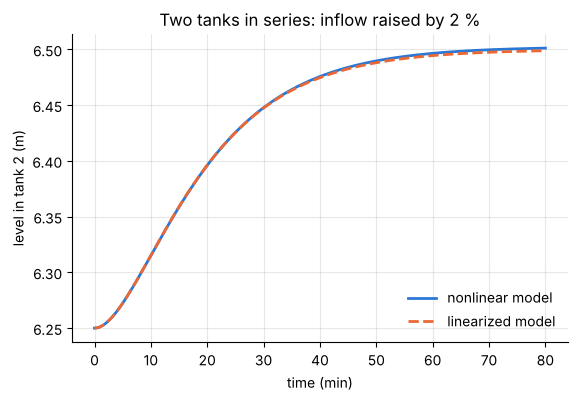

In [5]:
values = {A_1: 1.0, c_1: 0.5, A_2: 1.0, c_2: 0.4, q_s: 1.0}
levels = {h_1s: float(steady_levels[h_1].subs(values)), h_2s: float(steady_levels[h_2].subs(values))}
tau_1_val, tau_2_val = (float(tau.subs({**values, **levels})) for tau in (tau_1, tau_2))
K_2_val = 2 * np.sqrt(levels[h_2s]) / values[c_2]
print(f"h_1s = {levels[h_1s]:.2f} m   h_2s = {levels[h_2s]:.2f} m   tau_1 = {tau_1_val:.1f} min   tau_2 = {tau_2_val:.1f} min")

step = 0.02                                                 # m³/min
rate = sp.lambdify((h_1, h_2, q), list(tanks.subs(values)), "numpy")
times = np.linspace(0, 80, 400)
nonlinear = solve_ivp(lambda _, y: rate(*y, values[q_s] + step), [0, 80], [levels[h_1s], levels[h_2s]],
                      t_eval=times, rtol=1e-10, atol=1e-12).y[1]
linear = levels[h_2s] + K_2_val * step * (
    1 - (tau_1_val * np.exp(-times / tau_1_val) - tau_2_val * np.exp(-times / tau_2_val)) / (tau_1_val - tau_2_val))

# the eigenvalues of the numerical Jacobian, and agreement of the two responses within 3 % of the change
numeric_eigs = np.linalg.eigvals(np.array(J_tanks.subs({**values, **levels}), dtype=float))
assert np.allclose(sorted(numeric_eigs), sorted([-1 / tau_1_val, -1 / tau_2_val]))
assert np.abs(linear - nonlinear).max() < 0.03 * (nonlinear[-1] - levels[h_2s])

fig, ax = plt.subplots()
ax.plot(times, nonlinear, label="nonlinear model")
ax.plot(times, linear, ls="--", label="linearized model")
ax.set(xlabel="time (min)", ylabel="level in tank 2 (m)", title="Two tanks in series: inflow raised by 2 %")
ax.legend(frameon=False, loc="lower right");

**Answer.** The steady levels are $h_{1s} = q_s^2/c_1^2$ and $h_{2s} = q_s^2/c_2^2$. The Jacobian
is lower triangular with eigenvalues $-\dfrac{c_1}{2A_1\sqrt{h_{1s}}} = -\dfrac{1}{\tau_1}$ and
$-\dfrac{c_2}{2A_2\sqrt{h_{2s}}} = -\dfrac{1}{\tau_2}$: each tank contributes its own time constant
$\tau_i = 2A_i\sqrt{h_{is}}/c_i$. Both are real and negative, so the steady state is stable and
never oscillates. For the numbers used, $\tau_1 = 8$ min and $\tau_2 = 12.5$ min.

## Exercise 2

For the pendulum, find the damping coefficient at which the hanging equilibrium changes
from oscillatory to non-oscillatory.

In [6]:
theta, omega = sp.symbols("theta omega", real=True)
g, L, c_d = sp.symbols("g L c", positive=True)

state = sp.Matrix([theta, omega])
f = sp.Matrix([omega, -c_d * omega - g / L * sp.sin(theta)])

J_down = f.jacobian(state).subs({theta: 0, omega: 0})      # hanging down
eigenvalues = list(J_down.eigenvals())
J_down, eigenvalues

⎛           ⎡         ____________           ____________⎤⎞
⎜⎡ 0   1 ⎤  ⎢        ╱    2                 ╱    2       ⎥⎟
⎜⎢       ⎥  ⎢  c   ╲╱  L⋅c  - 4⋅g     c   ╲╱  L⋅c  - 4⋅g ⎥⎟
⎜⎢-g     ⎥, ⎢- ─ - ───────────────, - ─ + ───────────────⎥⎟
⎜⎢───  -c⎥  ⎣  2        2⋅√L          2        2⋅√L      ⎦⎟
⎝⎣ L     ⎦                                                ⎠

The eigenvalues are complex (oscillation) when the quantity under the square root is negative,
and real when it is positive. The change happens where it is zero, which is where the
discriminant of the characteristic polynomial vanishes.

In [7]:
lam = sp.symbols("lambda")
char_poly = J_down.charpoly(lam).as_expr()
c_crit = sp.solve(sp.discriminant(char_poly, lam), c_d)[0]
char_poly, c_crit

⎛       2   g  2⋅√g⎞
⎜c⋅λ + λ  + ─, ────⎟
⎝           L   √L ⎠

In [8]:
# verify: at c_crit the two eigenvalues coincide at -sqrt(g/L); with numbers, they are complex
# just below c_crit and real just above
assert sp.simplify(c_crit - 2 * sp.sqrt(g / L)) == 0
assert all(sp.simplify(e.subs(c_d, c_crit) + sp.sqrt(g / L)) == 0 for e in eigenvalues)

numbers = {g: 9.81, L: 1.0}
c_val = float(c_crit.subs(numbers))
below = [complex(e.subs({**numbers, c_d: 0.99 * c_val})) for e in eigenvalues]
above = [complex(e.subs({**numbers, c_d: 1.01 * c_val})) for e in eigenvalues]
assert all(abs(e.imag) > 0.1 for e in below) and all(e.imag == 0 and e.real < 0 for e in above)
print(f"g = 9.81 m/s², L = 1 m:  critical damping coefficient c = {c_val:.3f} 1/s")

g = 9.81 m/s², L = 1 m:  critical damping coefficient c = 6.264 1/s


**Answer.** $c = 2\sqrt{g/L}$. Below this value the eigenvalues are a complex pair and the
pendulum oscillates as it settles. Above it they are real and negative and it creeps back
without crossing the vertical. This is critical damping, $\zeta = 1$ with $\omega_n = \sqrt{g/L}$.
For the lesson's pendulum ($g = 9.81$ m/s², $L = 1$ m) it is $c = 6.26$ s$^{-1}$, far above the
value 0.5 s$^{-1}$ used in the phase portrait, which is why that portrait shows spirals.

## Exercise 3

The Lotka–Volterra model is $\dot x = x(a - b y)$, $\dot y = y(-c + d x)$. Find the
coexistence steady state and its eigenvalues. What does a zero real part tell you?

In [9]:
x, y = sp.symbols("x y", nonnegative=True)                # prey and predator populations
a, b, c, d = sp.symbols("a b c d", positive=True)

lotka_volterra = sp.Matrix([x * (a - b * y), y * (-c + d * x)])
steady_states = sp.solve(list(lotka_volterra), [x, y], dict=True)
steady_states

⎡              ⎧   c     a⎫⎤
⎢{x: 0, y: 0}, ⎨x: ─, y: ─⎬⎥
⎣              ⎩   d     b⎭⎦

In [10]:
coexistence = steady_states[1]
J_lv = lotka_volterra.jacobian([x, y])
J_lv.subs(coexistence), list(J_lv.subs(coexistence).eigenvals()), list(J_lv.subs(steady_states[0]).eigenvals())

⎛⎡     -b⋅c ⎤                              ⎞
⎜⎢ 0   ─────⎥                              ⎟
⎜⎢       d  ⎥                              ⎟
⎜⎢          ⎥, [-ⅈ⋅√a⋅√c, ⅈ⋅√a⋅√c], [a, -c]⎟
⎜⎢a⋅d       ⎥                              ⎟
⎜⎢───    0  ⎥                              ⎟
⎝⎣ b        ⎦                              ⎠

At coexistence the eigenvalues are $\pm i\sqrt{ac}$: purely imaginary. This is the last row of
the summary table. The linearization predicts oscillation at frequency $\sqrt{ac}$ but cannot say
whether it decays or grows, so the nonlinear terms decide.

For this model they can be examined exactly. The quantity
$H = d\,x - c\ln x + b\,y - a\ln y$ does not change along a solution:

In [11]:
H = d * x - c * sp.log(x) + b * y - a * sp.log(y)

dH_dt = H.diff(x) * lotka_volterra[0] + H.diff(y) * lotka_volterra[1]      # chain rule
assert sp.simplify(dH_dt) == 0
assert coexistence == {x: c / d, y: a / b}
assert set(J_lv.subs(coexistence).eigenvals()) == {sp.I * sp.sqrt(a * c), -sp.I * sp.sqrt(a * c)}

Every solution therefore stays on a contour of $H$, a closed curve around the steady state.
**Verify numerically** with $a = 1$, $b = 0.5$, $c = 0.5$, $d = 0.25$ (steady state at $x = y = 2$).

start x = 2.5:  H changes by 1.1e-10 over 40 time units,  period 8.916
start x = 4.0:  H changes by 2.0e-10 over 40 time units,  period 9.230
start x = 6.0:  H changes by 1.5e-09 over 40 time units,  period 9.912


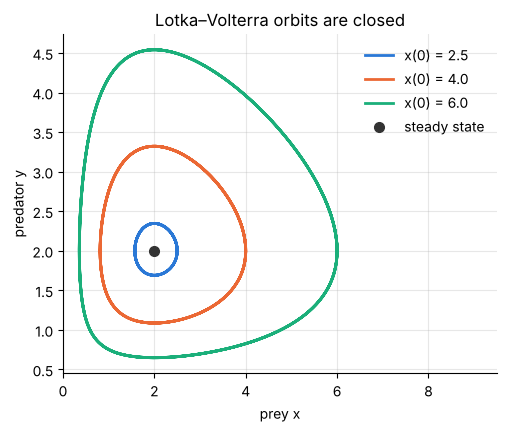

In [12]:
numbers = {a: 1.0, b: 0.5, c: 0.5, d: 0.25}
lv_fun = sp.lambdify((x, y), list(lotka_volterra.subs(numbers)), "numpy")
H_fun = sp.lambdify((x, y), H.subs(numbers), "numpy")

def passes_start(_, state):                                # prey rising through its steady value
    return state[0] - 2.0
passes_start.direction = 1

fig, ax = plt.subplots(figsize=(5.6, 4.4))
for x_start in (2.5, 4.0, 6.0):
    orbit = solve_ivp(lambda _, state: lv_fun(*state), [0, 40], [x_start, 2.0], events=passes_start,
                      t_eval=np.linspace(0, 40, 2000), rtol=1e-10, atol=1e-12)
    drift = np.ptp(H_fun(*orbit.y))
    period = np.diff(orbit.t_events[0])[0]
    print(f"start x = {x_start}:  H changes by {drift:.1e} over 40 time units,  period {period:.3f}")
    assert drift < 1e-7                                    # H is conserved: the orbit closes
    ax.plot(*orbit.y, label=f"x(0) = {x_start}")
ax.plot(2, 2, "o", color="0.2", ms=7, label="steady state")
ax.set(xlabel="prey x", ylabel="predator y", xlim=(0, 9.5), title="Lotka–Volterra orbits are closed")
ax.legend(frameon=False, loc="upper right")

# a small orbit has the period predicted by the linearization, 2 pi / sqrt(a c)
small = solve_ivp(lambda _, state: lv_fun(*state), [0, 40], [2.02, 2.0], events=passes_start, rtol=1e-10, atol=1e-12)
assert abs(np.diff(small.t_events[0])[0] - 2 * np.pi / np.sqrt(1.0 * 0.5)) < 1e-3

**Answer.** The coexistence steady state is $x = c/d$, $y = a/b$, with eigenvalues
$\pm i\sqrt{ac}$. (The other steady state, extinction at the origin, has eigenvalues $a$ and $-c$
and is a saddle.) A zero real part means that linearization cannot decide stability: it predicts
oscillations of period $2\pi/\sqrt{ac}$ that neither decay nor grow, and any small neglected term
could tip the balance. Here the conserved quantity $H$ settles the question. The orbits are
closed, so the populations cycle for ever with an amplitude set by the initial condition, and the
steady state is neutrally stable: disturbances neither die out nor grow. Larger orbits take
longer than the linear prediction of 8.89 time units.

## Exercise 4

Replace Monod kinetics in 9.3 by substrate inhibition,
$\mu = \dfrac{\mu_{max}\,s}{K_s + s + s^2/K_i}$ with $K_i = 2$ g/L and the other parameters
of 9.3. How many steady states are there at $D = 0.05$, $0.2$ and $0.4$ h⁻¹, and which are
stable? (Use numbers; the symbolic solution is long.)

The numbers are entered as exact fractions so that `solve` returns exact roots.

In [13]:
x, s = sp.symbols("x s", nonnegative=True)
D, mu_max, K_s, s_f, Y, K_i = sp.symbols("D mu_max K_s s_f Y K_i", positive=True)

mu = mu_max * s / (K_s + s + s**2 / K_i)
reactor = sp.Matrix([(mu - D) * x, D * (s_f - s) - mu * x / Y])
J_reactor = reactor.jacobian([x, s])

# 1/h, g/L, g/L, g cells per g substrate, g/L
params = {mu_max: sp.Rational(1, 2), K_s: sp.Rational(1, 5), s_f: 10, Y: sp.Rational(1, 2), K_i: 2}

With inhibition the growth rate is no longer monotonic. It rises to a maximum and then falls, so
the feed concentration is no longer where the cells grow fastest:

In [14]:
s_peak = sp.solve(sp.diff(mu, s), s)[0]
mu_peak = sp.simplify(mu.subs(s, s_peak))
mu_feed = mu.subs(s, s_f)
s_peak, mu_peak, float(s_peak.subs(params)), float(mu_peak.subs(params)), float(mu_feed.subs(params))

⎛                  ____   ____                                                 ↪
⎜  ____   ____   ╲╱ Kᵢ ⋅╲╱ Kₛ ⋅μₘₐₓ                                            ↪
⎜╲╱ Kᵢ ⋅╲╱ Kₛ , ────────────────────, 0.6324555320336759, 0.30628705663860345, ↪
⎜                 ____   ____                                                  ↪
⎝               ╲╱ Kᵢ ⋅╲╱ Kₛ  + 2⋅Kₛ                                           ↪

↪                     ⎞
↪                     ⎟
↪  0.08305647840531562⎟
↪                     ⎟
↪                     ⎠

The productive steady states satisfy $\mu(s) = D$, which is now a quadratic in $s$. Solve the
full model at three dilution rates: below $\mu(s_f) = 0.083$ h$^{-1}$, between $\mu(s_f)$ and the
peak $0.306$ h$^{-1}$, and above the peak. Because $x$ and $s$ are declared nonnegative, `solve`
discards roots with a negative concentration.

In [15]:
def classify(point, dilution):
    """Stability of a steady state from the eigenvalues of the Jacobian."""
    eigs = [complex(e) for e in J_reactor.subs({**params, D: dilution}).subs(point).eigenvals()]
    return "stable" if all(e.real < 0 for e in eigs) else "unstable"

found = {}
for dilution in (sp.Rational(1, 20), sp.Rational(1, 5), sp.Rational(2, 5)):
    points = sp.solve(list(reactor.subs({**params, D: dilution})), [x, s], dict=True)
    found[dilution] = [(float(pt[x]), float(pt[s]), classify(pt, dilution)) for pt in points]
    print(f"D = {float(dilution):.2f} 1/h: {len(points)} steady state(s)")
    for x_val, s_val, kind in found[dilution]:
        print(f"    x = {x_val:5.3f} g/L   s = {s_val:6.3f} g/L   {kind}")

D = 0.05 1/h: 2 steady state(s)
    x = 0.000 g/L   s = 10.000 g/L   unstable
    x = 4.989 g/L   s =  0.022 g/L   stable


D = 0.20 1/h: 3 steady state(s)
    x = 0.000 g/L   s = 10.000 g/L   stable
    x = 4.930 g/L   s =  0.140 g/L   stable
    x = 3.570 g/L   s =  2.860 g/L   unstable
D = 0.40 1/h: 1 steady state(s)
    x = 0.000 g/L   s = 10.000 g/L   stable


In [16]:
# verify: the counts follow from where D lies relative to mu(s_f) and the peak of mu;
# every reported state makes the right-hand side vanish; and the stability pattern is as expected
assert float(mu_feed.subs(params)) < 0.2 < float(mu_peak.subs(params))
assert [len(found[dil]) for dil in found] == [2, 3, 1]

rhs_fun = sp.lambdify((x, s), list(reactor.subs({**params, D: 0.2})), "numpy")
for x_val, s_val, _ in found[sp.Rational(1, 5)]:
    assert np.allclose(rhs_fun(x_val, s_val), 0, atol=1e-12)
assert sorted(kind for *_, kind in found[sp.Rational(1, 5)]) == ["stable", "stable", "unstable"]

At $D = 0.2$ h$^{-1}$ there are two stable states, washout and a productive one, with an
unstable state between them. Which one the reactor reaches depends on how it is started.
**Verify by simulation** from two initial conditions.

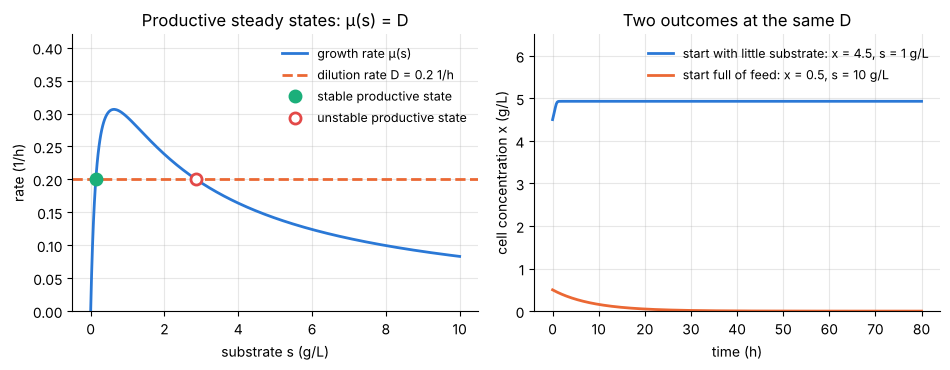

In [17]:
starts = {"start with little substrate: x = 4.5, s = 1 g/L": [4.5, 1.0],
          "start full of feed: x = 0.5, s = 10 g/L": [0.5, 10.0]}
times = np.linspace(0, 80, 400)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
s_grid = np.linspace(0, 10, 400)
axes[0].plot(s_grid, sp.lambdify(s, mu.subs(params), "numpy")(s_grid), label="growth rate μ(s)")
axes[0].axhline(0.2, color="#eb6834", ls="--", label="dilution rate D = 0.2 1/h")
for x_val, s_val, kind in [pt for pt in found[sp.Rational(1, 5)] if pt[0] > 0]:      # the productive states, where μ(s) = D
    axes[0].plot(s_val, 0.2, "o", ms=8, mew=2, mfc="#1baf7a" if kind == "stable" else "white",
                 mec="#1baf7a" if kind == "stable" else "#e34948", label=f"{kind} productive state")
axes[0].set(xlabel="substrate s (g/L)", ylabel="rate (1/h)", ylim=(0, 0.42), title="Productive steady states: μ(s) = D")
axes[0].legend(frameon=False, loc="upper right", fontsize=9)

ends = []
for label, start in starts.items():
    run = solve_ivp(lambda _, state: rhs_fun(*state), [0, 80], start, t_eval=times, rtol=1e-9, atol=1e-11)
    ends.append(run.y[:, -1])
    axes[1].plot(times, run.y[0], label=label)
axes[1].set(xlabel="time (h)", ylabel="cell concentration x (g/L)", ylim=(0, 6.5), title="Two outcomes at the same D")
axes[1].legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()

productive = [pt for pt in found[sp.Rational(1, 5)] if pt[0] > 0 and pt[2] == "stable"][0]
assert np.allclose(ends[0], productive[:2], atol=1e-3)     # reaches the stable productive state
assert ends[1][0] < 0.01 and abs(ends[1][1] - 10) < 0.01   # washes out

**Answer.** With $K_i = 2$ g/L and the other parameters of 9.3, the number depends on the
dilution rate, because $\mu(s)$ now has a maximum $\mu_{peak} = 0.306$ h$^{-1}$ at
$s = \sqrt{K_sK_i} = 0.63$ g/L and falls to $\mu(s_f) = 0.083$ h$^{-1}$ at the feed concentration.

- $D < \mu(s_f)$: two steady states, an unstable washout and a stable productive state, as with
  Monod kinetics.
- $\mu(s_f) < D < \mu_{peak}$: **three** steady states. At $D = 0.2$ h$^{-1}$ they are washout
  ($x = 0$, $s = 10$ g/L, stable), a productive state ($x = 4.93$, $s = 0.14$ g/L, stable) and an
  intermediate state ($x = 3.57$, $s = 2.86$ g/L, unstable).
- $D > \mu_{peak}$: washout only.

In the middle range the reactor is bistable. A disturbance that raises the substrate
concentration far enough, or a start-up with the tank full of feed, sends it to washout even
though a productive state exists at the same dilution rate.